# Statistical Arbitrage on S&P 500 Equities — Part 2: Cross-sectional Residual Model
### PCA factor-adjusted z-score, dollar- and sector-neutral, net of transaction and borrow costs

Part 1 (`01_pairs_trading.ipynb`) traded one spread per pair of stocks. This notebook extends the same framework
to the **whole universe at once**: every stock gets a score for how far its *idiosyncratic* price has drifted from
what its common factors explain, and we go long the cheapest and short the richest names within each sector.
It follows Phases 7–10 of `phases.txt`.

**Same framework as Part 1:** same 420-stock universe and data, same walk-forward loop (252-day estimation,
63-day trading window), same PnL engine and the same costs. Only the signal changes. The data loading and the
engine are repeated here so this notebook runs on its own.

**How to read the results.** As in Part 1, parameters were chosen on **2011–2018** (development) and **2019–2026**
is reported as a holdout.

### Results at a glance (2011–2026, out-of-sample, 5 bps per dollar traded + 50 bps/yr borrow)

| | Cross-sectional book |
|---|---|
| Gross Sharpe (before costs), development / holdout | +0.72 / +0.87 |
| Net Sharpe, full period | −0.04 |
| Net Sharpe, development 2011–18 / holdout 2019–26 | −0.44 / +0.20 |
| Break-even cost per dollar traded | ~5 bps (net Sharpe +0.25 at 3 bps) |
| Beta to SPY | +0.04 |
| Dollar / sector neutrality, 2% name cap | exact at every trade (asserted) |

The residual z-score clearly predicts returns (a random signal with the same turnover earns nothing). The edge per
trade is small, so the book is break-even at 5 bps and profitable only with cheap execution (≤ 3 bps).

## What changed from the previous version

| Problem in the previous version (now removed) | Fix here |
|---|---|
| The cross-sectional model drifted from the spec: linear weights, no deciles, no half-life filter, an extra leverage rule, and settings chosen while looking at holdout numbers. | Implemented **as specified**: PCA → residual → half-life filter → z-score → sector-neutral deciles, 2% cap, rebalance band. Parameters chosen on 2011–18 only. |
| Residuals used each day's own return to fit that day's factor model. | PCA fitted on a trailing window, then **frozen** for the next 63 days (same walk-forward loop as the pairs). |
| The PnL engine rebalanced to constant weights every day without charging for it. | The engine **holds shares** between trades and charges costs on every dollar actually traded. Unit-tested against a hand calculation. |

---
## Phase 0 — Setup

**Every tunable number lives in this one cell.** If you want to change anything, change it here and re-run the
notebook top to bottom.

A word on **costs**, because they decide whether a stat-arb strategy makes money:

* Each time we trade $1 of stock we pay **commission + half the bid-ask spread + slippage**. For S&P 500 names
  during 2011–2026, quoted half-spreads are typically 1–2 bps and institutional commissions well under 1 bp.
  We use **1 + 2 + 2 = 5 bps per dollar traded**, which is deliberately on the conservative side.
  (the previous version used 10 bps, which is more like small-cap or 2000s costs; the robustness section shows results at 0, 3, 5 and 10 bps.)
* Short positions pay a **borrow fee**: 50 bps per year for general-collateral S&P 500 names.

In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ---------------- data ----------------
DATA_DIR = Path("data")
DATA_START = "2010-01-01"
MAX_MISSING_PCT = 0.05          # drop tickers missing more than 5% of days
DEV_END = "2018-12-31"          # parameters chosen on <= this date; later dates are the holdout
TRADING_DAYS = 252

# ---------------- walk-forward windows (trading days) ----------------
FORMATION_WINDOW = 252          # 1 year of history to fit the factor model
TRADING_WINDOW = 63             # 1 quarter traded out-of-sample, then everything is re-estimated

# ---------------- cross-sectional residual model ----------------
PCA_WINDOW = 252                # trailing returns used for PCA
PCA_VAR_TARGET = 0.55           # keep factors explaining ~55% of variance
PCA_MAX_FACTORS = 15
OU_WINDOW = 60                  # cumulative-residual lookback for the half-life / z-score
XS_MAX_HALF_LIFE = 40           # discard names whose residual half-life is longer
XS_DECILE = 0.10                # long bottom 10%, short top 10% (within each sector)
XS_REBALANCE_BAND = 2.0         # only change a position once its z-score moved > 2.0 since entry
XS_GROSS = 1.0                  # target book: 50% long + 50% short of NAV (held positions make it ~2x on average)
MAX_NAME_WEIGHT = 0.02          # no name may exceed 2% of the book

# ---------------- costs ----------------
COMMISSION_BPS = 1.0
HALF_SPREAD_BPS = 2.0
SLIPPAGE_BPS = 2.0
BORROW_BPS_ANNUAL = 50.0
COST_BPS = COMMISSION_BPS + HALF_SPREAD_BPS + SLIPPAGE_BPS   # per dollar traded, each leg

RANDOM_SEED = 42
print(f"All-in trading cost: {COST_BPS:.0f} bps per dollar traded; borrow {BORROW_BPS_ANNUAL:.0f} bps/yr on shorts")

All-in trading cost: 5 bps per dollar traded; borrow 50 bps/yr on shorts


---
## Data (same as Part 1)

**Universe.** We do not have point-in-time S&P 500 membership, so we take the **current S&P 500 constituents
that have a full price history since January 2010** (420 names; for Alphabet we keep only one share class). *This introduces survivorship bias: every name
is a company that survived and stayed large until today.* For a long-only strategy that bias flatters returns a
lot; for a sector-neutral long/short book it matters much less (both legs are survivors), but it is still a
caveat.

**Prices.** Daily closes adjusted for splits *and dividends* (Yahoo `auto_adjust=True`), which is a total-return
proxy. Raw prices would create fake "divergences" every time a stock goes ex-dividend.

**Classification.** GICS **sector** (11 groups) and GICS **sub-industry** (~120 groups) from the S&P 500
constituent list. The book is neutral by sector.

The data is cached in `data/`. If the cache is missing, the cell downloads it again (needs internet).

In [2]:
def load_sp500_universe(cache=DATA_DIR / "sp500_prices.pkl", list_cache=DATA_DIR / "sp500_list.pkl"):
    """Adjusted Close and Open for S&P 500 names + GICS sector / sub-industry. Cached to disk."""
    if list_cache.exists():
        meta = pd.read_pickle(list_cache)
    else:
        import io, requests
        html = requests.get("https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
                            headers={"User-Agent": "Mozilla/5.0"}).text
        meta = (pd.read_html(io.StringIO(html))[0]
                .rename(columns={"Symbol": "ticker", "GICS Sector": "sector", "GICS Sub-Industry": "sub_industry"}))
        meta["ticker"] = meta.ticker.str.replace(".", "-", regex=False)
        meta = meta.set_index("ticker")[["sector", "sub_industry"]]
        meta.to_pickle(list_cache)

    if cache.exists():
        raw = pd.read_pickle(cache)
    else:
        import yfinance as yf
        dl = yf.download(sorted(meta.index), start=DATA_START, auto_adjust=True,
                         progress=False, group_by="ticker", threads=True)
        have = [t for t in meta.index if t in dl.columns.get_level_values(0)]
        raw = {f: pd.concat({t: dl[t][f] for t in have}, axis=1).sort_index() for f in ("Close", "Open")}
        pd.to_pickle(raw, cache)
    return raw["Close"], raw["Open"], meta


def load_spy(cache=DATA_DIR / "spy.pkl"):
    if cache.exists():
        return pd.read_pickle(cache)["Close"]["SPY"]
    import yfinance as yf
    spy = yf.download("SPY", start=DATA_START, auto_adjust=True, progress=False)["Close"]
    pd.to_pickle({"Close": spy.rename(columns=lambda _: "SPY") if isinstance(spy, pd.DataFrame) else spy.to_frame("SPY")}, cache)
    return load_spy(cache)


close_raw, open_raw, meta = load_sp500_universe()

# keep names that existed from the start and have <5% missing days; fill the rare gap with the last price
first_seen = close_raw.apply(lambda s: s.first_valid_index())
full_history = first_seen[first_seen <= pd.Timestamp(DATA_START) + pd.Timedelta(days=20)].index
prices = close_raw[full_history]
prices = prices.loc[:, prices.isna().mean() <= MAX_MISSING_PCT].ffill().dropna()
# second share classes of the same company (GOOG = GOOGL) are not a "pair", they are one stock: keep one class
prices = prices.drop(columns=[t for t in ("GOOG", "FOX", "NWS") if t in prices.columns])
opens = open_raw.reindex(index=prices.index, columns=prices.columns).ffill()

SECTOR = meta.sector.reindex(prices.columns)
SUB_INDUSTRY = meta.sub_industry.reindex(prices.columns)
spy = load_spy().reindex(prices.index).ffill()
spy_ret = spy.pct_change().fillna(0.0)

log_prices = np.log(prices)
returns = prices.pct_change()

print(f"Universe: {prices.shape[1]} stocks, {SECTOR.nunique()} sectors, {SUB_INDUSTRY.nunique()} sub-industries")
print(f"Dates:    {prices.index[0].date()} -> {prices.index[-1].date()}  ({len(prices)} trading days)")
SECTOR.value_counts().to_frame("stocks").T

Universe: 420 stocks, 11 sectors, 118 sub-industries
Dates:    2010-01-05 -> 2026-09-14  (4198 trading days)


sector,Industrials,Financials,Information Technology,Health Care,Consumer Discretionary,Consumer Staples,Utilities,Real Estate,Materials,Energy,Communication Services
stocks,68,65,57,51,39,32,29,28,21,15,15


---
## PnL engine (same as Part 1)

One function turns **daily target weights** (fraction of NAV, decided at each close) and **prices** into a daily
equity curve. It is the same engine as Part 1, tested again here against the same hand calculation.

How it works, day by day:

1. **Mark to market.** Yesterday's dollar holdings earn today's return: $\text{PnL}_t = \sum_i h_{i,t-1} r_{i,t}$.
   Holdings then drift with prices (we hold *shares*, not constant weights).
2. **Borrow.** Every short position pays `BORROW_BPS_ANNUAL / 252` per day on its dollar value.
3. **Trade.** For every stock whose *target* changed today, trade to target × NAV. Stocks whose target did not
   change are left alone (no hidden daily rebalancing).
4. **Costs.** Every dollar traded pays commission + half-spread + slippage.

**Timing.** Weights decided at the close of day *t* (using prices up to *t*) are executed at that close
(market-on-close) and first earn the return of day *t+1*. A signal never earns the return of the bar it was
computed on. (The robustness section also shows the more conservative "execute at the next day's open".)

In [3]:
def run_backtest(weights, prices, cost_bps=COST_BPS, borrow_bps=BORROW_BPS_ANNUAL):
    """Daily target weights (fraction of NAV) + prices -> daily PnL table (NAV starts at 1)."""
    W = weights.reindex(index=prices.index, columns=prices.columns).fillna(0.0).to_numpy()
    R = prices.pct_change().fillna(0.0).to_numpy()
    cost, borrow_daily = cost_bps / 1e4, borrow_bps / 1e4 / TRADING_DAYS

    nav, h, prev_target = 1.0, np.zeros(W.shape[1]), np.zeros(W.shape[1])
    rows = []
    for t in range(len(W)):
        nav_start = nav
        pnl = h @ R[t]                                   # 1) mark to market
        borrow = np.clip(-h, 0, None).sum() * borrow_daily   # 2) borrow on shorts
        h = h * (1 + R[t])
        nav = nav + pnl - borrow
        changed = W[t] != prev_target                    # 3) trade only names whose target changed
        new_h = np.where(changed, W[t] * nav, h)
        traded = np.abs(new_h - h).sum()
        tc = traded * cost                               # 4) costs on dollars traded
        nav -= tc
        h, prev_target = new_h, W[t]
        rows.append((pnl / nav_start, tc / nav_start, borrow / nav_start, traded / nav_start,
                     np.abs(h).sum() / nav, h.sum() / nav))

    out = pd.DataFrame(rows, index=prices.index,
                       columns=["gross_ret", "cost", "borrow", "turnover", "gross_exposure", "net_exposure"])
    out["net_ret"] = out.gross_ret - out.cost - out.borrow
    out["equity"] = (1 + out.net_ret).cumprod()
    out["gross_equity"] = (1 + out.gross_ret).cumprod()
    return out

**Unit test with a known answer** (from `phases.txt`). Stock A goes 100 → 110 and stock B 100 → 95 over three
days. At the close of day 0 we go long $0.50 of A and short $0.50 of B; at the close of day 3 we close both.

By hand:
* Gross PnL: A earns 10% on $0.50 = **+$0.050**, the B short earns 5% on $0.50 = **+$0.025** → **+$0.075**.
* Entry cost: we trade $0.50 + $0.50 = $1.00 → $1.00 × 5 bps.
* Exit cost: A is now worth $0.55 and the B short $0.475 → we trade $1.025 → $1.025 × 5 bps.
* Borrow: on the short's value at the start of each held day: ($0.50 + $0.49 + $0.48) × 50 bps / 252.

In [4]:
idx = pd.date_range("2020-01-01", periods=5, freq="D")
px_test = pd.DataFrame({"A": [100, 104, 107, 110, 110], "B": [100, 98, 96, 95, 95]}, index=idx, dtype=float)
w_test = pd.DataFrame({"A": [0.5, 0.5, 0.5, 0.0, 0.0], "B": [-0.5, -0.5, -0.5, 0.0, 0.0]}, index=idx)
res = run_backtest(w_test, px_test)

c, b = COST_BPS / 1e4, BORROW_BPS_ANNUAL / 1e4 / TRADING_DAYS
gross_pnl = 0.5 * 0.10 + 0.5 * 0.05
cost_total = 1.00 * c + 1.025 * c
borrow_total = (0.50 + 0.49 + 0.48) * b
expected_nav = 1 + gross_pnl - cost_total - borrow_total
engine_nav = res.equity.iloc[-1]

print(f"hand calculation: gross +{gross_pnl:.4f}  costs -{cost_total:.6f}  borrow -{borrow_total:.6f}  -> NAV {expected_nav:.8f}")
print(f"engine:                                                               -> NAV {engine_nav:.8f}")
assert np.isclose(engine_nav, expected_nav, atol=1e-12), "PnL engine disagrees with the hand calculation"
assert np.isclose((res.cost * res.equity.shift(1, fill_value=1)).sum(), cost_total, atol=1e-12)
assert res.gross_ret.iloc[0] == 0, "nothing can be earned on the day the position is opened"
print("PnL engine: all asserts pass")
res.round(6)

hand calculation: gross +0.0750  costs -0.001012  borrow -0.000029  -> NAV 1.07395833
engine:                                                               -> NAV 1.07395833
PnL engine: all asserts pass


,gross_ret,cost,borrow,turnover,gross_exposure,net_exposure,net_ret,equity,gross_equity
2020-01-01,0.000000,0.000500,0.000000,1.000000,1.000500,0.000000,-0.000500,0.999500,1.000000
2020-01-02,0.030015,0.000000,0.000010,0.000000,0.981068,0.029141,0.030005,1.029490,1.030015
2020-01-03,0.024284,0.000000,0.000009,0.000000,0.962559,0.052158,0.024274,1.054480,1.055028
2020-01-04,0.018967,0.000486,0.000009,0.972043,0.000000,0.000000,0.018472,1.073958,1.075038
2020-01-05,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.073958,1.075038


**Performance statistics** (same definitions as Part 1). Sharpe = mean daily return / std × √252 (risk-free rate
ignored: a dollar-neutral book is self-financing). Max drawdown = worst peak-to-trough fall. Turnover = dollars
traded per year / NAV. SPY is shown for scale only: a market-neutral book tries to earn a return that is
*uncorrelated* with the index, not to beat it.

In [5]:
def sharpe(r):
    return r.mean() / r.std() * np.sqrt(TRADING_DAYS) if r.std() > 0 else np.nan


def max_drawdown(r):
    eq = (1 + r).cumprod()
    return (eq / eq.cummax() - 1).min()


def ann_return(r):
    return (1 + r).prod() ** (TRADING_DAYS / len(r)) - 1



def yearly_table(bt, spy_ret, trades=None):
    """Calendar-year performance, gross and net, vs SPY; last row = full period."""
    rows = {}
    for label, chunk in list(bt.groupby(bt.index.year)) + [("ALL", bt)]:
        s = spy_ret.loc[chunk.index]
        row = {"gross ret": ann_return(chunk.gross_ret), "gross Sharpe": sharpe(chunk.gross_ret),
               "net ret": ann_return(chunk.net_ret), "net Sharpe": sharpe(chunk.net_ret),
               "net max DD": max_drawdown(chunk.net_ret),
               "turnover (x/yr)": chunk.turnover.sum() * TRADING_DAYS / len(chunk),
               "days up": (chunk.net_ret > 0).sum() / (chunk.net_ret != 0).sum()}
        if trades is not None:
            t = trades if label == "ALL" else trades[trades.entry.dt.year == label]
            row["trades"] = len(t)
            row["hit rate"] = (t.ret > 0).mean() if len(t) else np.nan
        row.update({"SPY ret": ann_return(s), "SPY Sharpe": sharpe(s)})
        rows[label] = row
    return pd.DataFrame(rows).T


def style_table(df):
    pct = [c for c in df.columns if "ret" in c or "DD" in c or "rate" in c or "days up" in c]
    fmt = {c: "{:+.1%}" for c in pct} | {c: "{:+.2f}" for c in df.columns if "Sharpe" in c}
    fmt |= {c: "{:.0f}" for c in df.columns if c in ("trades", "turnover (x/yr)")}
    return df.style.format(fmt, na_rep="-")


def period_split(r):
    """Sharpe on the development period, the holdout, and both."""
    return pd.Series({"dev 2011-18": sharpe(r.loc[:DEV_END]), "holdout 2019-26": sharpe(r.loc[DEV_END:].iloc[1:]),
                      "full": sharpe(r)})



def plot_equity(bt, title, spy_ret):
    spy_eq = (1 + spy_ret.loc[bt.index]).cumprod()
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    ax1.plot(bt.index, bt.gross_equity, label="gross of costs", lw=1.2)
    ax1.plot(bt.index, bt.equity, label="net of costs", lw=1.5)
    ax1b = ax1.twinx()
    ax1b.plot(spy_eq.index, spy_eq, color="0.6", lw=0.8, label="SPY (right axis)")
    ax1b.grid(False)
    ax1.axvline(pd.Timestamp(DEV_END), color="k", ls=":", lw=1)
    ax1.text(pd.Timestamp(DEV_END), ax1.get_ylim()[1], " holdout →", va="top", fontsize=9)
    ax1.set_ylabel("strategy NAV"); ax1b.set_ylabel("SPY NAV")
    ax1.set_title(title)
    h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax1b.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper left")
    ax2.fill_between(bt.index, bt.equity / bt.equity.cummax() - 1, 0, alpha=0.5, label="strategy (net)")
    ax2.plot(spy_eq.index, spy_eq / spy_eq.cummax() - 1, color="0.6", lw=0.8, label="SPY")
    ax2.set_ylabel("drawdown"); ax2.legend(loc="lower left")
    plt.tight_layout(); plt.show()



def half_life_from_gamma(gamma):
    """Days for a deviation to halve when each day it shrinks by a factor (1 + gamma), -1 < gamma < 0.
    Exact for daily data: (1 + gamma)^H = 1/2  ->  H = -ln 2 / ln(1 + gamma)  (~ ln 2 / |gamma| when gamma is small)."""
    gamma = np.asarray(gamma, float)
    ok = (gamma < 0) & (gamma > -1)
    return np.where(ok, -np.log(2) / np.log1p(np.where(ok, gamma, -0.5)), np.inf)

---
## Phase 7 — Cross-sectional residual model

**Same walk-forward loop as Part 1 (252-day estimation, 63-day trading window), same PnL engine, same costs.**
Only the signal changes: instead of one spread per pair, every stock gets a score for how far its *idiosyncratic* price
has moved away from where its factors say it should be.

**Step 1 — PCA factors (estimated on the trailing 252 days, then frozen for the next 63).**
Standardise each stock's daily returns, take the correlation matrix, and keep the top principal components until
they explain ~55% of the variance (≈ 7–15 factors; the first one is "the market", the next ones are sector /
style themes). Each component defines an *eigenportfolio* $Q_j = v_j / \sigma_i$; its daily return is a factor
return $F_{j,t}$.

**Step 2 — residual returns.** Regress each stock on the factors over the estimation window to get its loadings
$\beta_{i,j}$. Out of sample, the residual is $e_{i,t} = r_{i,t} - \sum_j \beta_{i,j} F_{j,t}$ — the part of today's
return the factors do not explain. Loadings are frozen, so the residual is genuinely out-of-sample.

**Step 3 — cumulative residual, half-life, z-score** (Avellaneda & Lee 2010 "s-score"). Over the last 60 days,
cumulate the residuals into $X_t$ (an idiosyncratic "price"). Fit $X_{t+1} = a + bX_t + \zeta$
(the same half-life regression as for the pairs in Part 1, with $\gamma = b - 1$, $H = -\ln 2/\ln(1+\gamma)$). **Discard stocks with H > 40 days.**
The equilibrium is $m = a/(1-b)$ and its stationary std $\sigma_{eq} = \sqrt{\mathrm{Var}(\zeta)/(1-b^2)}$, so
$$z_t = \frac{X_t - m}{\sigma_{eq}}$$
Negative z: the stock is cheap relative to its factors → expected to bounce. Positive z: rich → expected to fall.

**Step 4 — portfolio.**
* Rank by z **within each GICS sector**; long the bottom decile, short the top decile.
* **Equal dollars per name**, and in every sector the number of longs equals the number of shorts (extra names
  on the heavier side, the least extreme ones, are dropped) → **dollar-neutral and sector-neutral by construction**.
* **2% cap:** no name may exceed 2% of the book (asserted below).
* **Rebalance band:** a position is only changed once its z-score has moved by more than `XS_REBALANCE_BAND`
  since entry; otherwise it is held. Without this the book churns daily on noise and costs eat everything.
  `phases.txt` suggested 0.5. On the development period that churned the book (~240x NAV a year) and lost
  money net, so we use **2.0**: a long entered at z ≈ −1.5 is closed once z has come back above ≈ +0.5 (the
  mispricing is gone) or fallen below ≈ −3.5 (it is not reverting). The robustness section shows 0.5, 1, 2 and 3.
* **Equal dollars per name, fixed size.** Each position is `XS_GROSS / 2 / (10% of the universe)` of NAV and is
  never resized while held, so the only trades are genuine entries and exits.

In [6]:
def pca_residuals(returns, est=PCA_WINDOW, refit=TRADING_WINDOW, var_target=PCA_VAR_TARGET, max_k=PCA_MAX_FACTORS):
    """Walk-forward PCA residuals: fit on `est` trailing days, apply the frozen model to the next `refit` days."""
    R = returns.to_numpy()
    T, N = R.shape
    resid, n_factors = np.full((T, N), np.nan), np.full(T, np.nan)
    for s in range(est, T, refit):
        W = R[s - est:s]
        mu, sd = W.mean(0), W.std(0, ddof=1)
        corr = np.corrcoef(W, rowvar=False)
        vals, vecs = np.linalg.eigh(corr)
        vals, vecs = vals[::-1], vecs[:, ::-1]                       # largest first
        k = int(min(max_k, np.searchsorted(np.cumsum(vals) / vals.sum(), var_target) + 1))
        Q = vecs[:, :k] / sd[:, None]                                # eigenportfolio weights
        F = W @ Q                                                    # factor returns, estimation window
        loadings = np.linalg.lstsq(np.column_stack([np.ones(est), F]), W, rcond=None)[0][1:]
        R_out = R[s:s + refit]
        resid[s:s + refit] = R_out - (R_out @ Q) @ loadings          # out-of-sample residuals
        n_factors[s:s + refit] = k
    return pd.DataFrame(resid, index=returns.index, columns=returns.columns), pd.Series(n_factors, index=returns.index)


def residual_zscore(resid, window=OU_WINDOW):
    """Rolling AR(1) fit of the cumulative residual over `window` days -> (z-score, half-life).

    Uses rolling sums so every stock and every day is done at once. The cumulative residual's starting point
    does not matter: shifting X by a constant shifts the intercept a and the mean m by the same amount."""
    X = resid.fillna(0).cumsum().where(resid.notna())
    x, y, n = X.shift(1), X, window - 1
    mx, my = x.rolling(n).mean(), y.rolling(n).mean()
    cov_xy = (x * y).rolling(n).mean() - mx * my
    var_x = (x * x).rolling(n).mean() - mx ** 2
    var_y = (y * y).rolling(n).mean() - my ** 2
    b = cov_xy / var_x
    a = my - b * mx
    var_zeta = (var_y - b * cov_xy) * n / (n - 2)
    m = a / (1 - b)
    sigma_eq = np.sqrt(var_zeta / (1 - b ** 2))
    z = (X - m) / sigma_eq
    hl = pd.DataFrame(half_life_from_gamma(b - 1), index=b.index, columns=b.columns)   # gamma = b - 1
    return z, hl.where(b > 0)


def sector_neutral_decile_book(z, hl, sector, q=XS_DECILE, max_hl=XS_MAX_HALF_LIFE, band=XS_REBALANCE_BAND,
                               gross=XS_GROSS):
    """Daily target weights: sticky long/short deciles within each sector, equal $ per name, #long = #short per sector."""
    Z, H = z.to_numpy(), hl.to_numpy()
    T, N = Z.shape
    sec = sector.reindex(z.columns).to_numpy()
    groups = [np.where(sec == g)[0] for g in pd.unique(sec)]
    unit = gross / 2 / round(q * N)                       # dollars per name (fraction of NAV), never changes
    side, z_entry = np.zeros(N), np.zeros(N)
    out = np.zeros((T, N))
    for t in range(T):
        zt = Z[t]
        has_z = np.isfinite(zt)
        if has_z.sum() < 50:                               # not enough history yet
            side[:] = 0
            continue
        tradable = has_z & np.isfinite(H[t]) & (H[t] <= max_hl)
        # 1) today's target: bottom / top decile of tradable names, within each sector
        target = np.zeros(N)
        for g in groups:
            gi = g[tradable[g]]
            if len(gi) < 4:
                continue
            k = max(1, int(round(q * len(gi))))
            order = gi[np.argsort(zt[gi])]
            target[order[:k]], target[order[-k:]] = 1, -1
        # 2) exits: held names no longer in their decile, but only once z moved more than `band` since entry
        leave = (side != 0) & (target != side) & ((np.abs(zt - z_entry) > band) | ~has_z)
        side[leave] = 0
        # 3) entries: flat names that are in a decile today
        enter = (side == 0) & (target != 0)
        side[enter], z_entry[enter] = target[enter], zt[enter]
        # 4) sector neutrality: equal number of longs and shorts in each sector
        for g in groups:
            longs, shorts = g[side[g] == 1], g[side[g] == -1]
            extra = len(longs) - len(shorts)
            if extra > 0:     # drop the least cheap longs
                side[longs[np.argsort(-zt[longs])][:extra]] = 0
            elif extra < 0:   # drop the least rich shorts
                side[shorts[np.argsort(zt[shorts])][:-extra]] = 0
        out[t] = side * unit
    return pd.DataFrame(out, index=z.index, columns=z.columns)


t0 = time.time()
resid, n_factors = pca_residuals(returns.iloc[1:])
xs_z, xs_hl = residual_zscore(resid)
xs_z, xs_hl = xs_z.reindex(prices.index), xs_hl.reindex(prices.index)
xs_w = sector_neutral_decile_book(xs_z, xs_hl, SECTOR)
xs_w = xs_w.loc[xs_w.abs().sum(axis=1).gt(0).idxmax():]          # start on the first active day
xs_bt = run_backtest(xs_w, prices.loc[xs_w.index])
print(f"built in {time.time() - t0:.0f}s;  PCA factors kept: median {n_factors.median():.0f} "
      f"(range {n_factors.min():.0f}-{n_factors.max():.0f});  residual half-life median {np.nanmedian(xs_hl):.1f}d, "
      f"{np.mean(xs_hl.to_numpy()[np.isfinite(xs_hl.to_numpy())] <= XS_MAX_HALF_LIFE):.0%} of stock-days pass the 40d filter")

built in 3s;  PCA factors kept: median 10 (range 1-15);  residual half-life median 8.8d, 93% of stock-days pass the 40d filter


**Checks — are the constraints actually enforced?** On every day, target weights must sum to zero overall and
within every sector, and no name may exceed 2% of the book.

In [7]:
active = xs_w[xs_w.abs().sum(axis=1) > 0]
sector_net = active.T.groupby(SECTOR).sum().T.abs().max().max()
name_share = active.abs().max().max() / XS_GROSS               # largest name as a share of the (target) book
assert active.sum(axis=1).abs().max() < 1e-12, "book is not dollar-neutral"
assert sector_net < 1e-12, "book is not sector-neutral"
assert name_share <= MAX_NAME_WEIGHT, "a name exceeds the 2% cap"
actual_share = active.abs().div(active.abs().sum(axis=1), axis=0).max(axis=1)
print(f"largest name as a share of the book actually held that day: median {actual_share.median():.2%}, "
      f"worst day {actual_share.max():.2%}")
print(f"max |net $| = {active.sum(axis=1).abs().max():.1e},  max |sector net $| = {sector_net:.1e},  "
      f"largest single name = {name_share:.2%} of the book ({XS_GROSS:.0%} of NAV)")
print(f"names held per side: {(active > 0).sum(axis=1).mean():.0f} long / {(active < 0).sum(axis=1).mean():.0f} short on average; "
      f"gross exposure {xs_bt.gross_exposure.mean():.0%} of NAV")

largest name as a share of the book actually held that day: median 0.60%, worst day 1.61%
max |net $| = 1.4e-17,  max |sector net $| = 0.0e+00,  largest single name = 1.19% of the book (100% of NAV)
names held per side: 82 long / 82 short on average; gross exposure 197% of NAV


In [8]:
xs_year = yearly_table(xs_bt, spy_ret)
print("CROSS-SECTIONAL book: Sharpe by period (net):", period_split(xs_bt.net_ret).round(2).to_dict())
print("CROSS-SECTIONAL book: Sharpe by period (gross):", period_split(xs_bt.gross_ret).round(2).to_dict())
style_table(xs_year)

CROSS-SECTIONAL book: Sharpe by period (net): {'dev 2011-18': -0.44, 'holdout 2019-26': 0.2, 'full': -0.04}
CROSS-SECTIONAL book: Sharpe by period (gross): {'dev 2011-18': 0.72, 'holdout 2019-26': 0.87, 'full': 0.79}


,gross ret,gross Sharpe,net ret,net Sharpe,net max DD,turnover (x/yr),days up,SPY ret,SPY Sharpe
2011,+7.5%,+1.44,+2.7%,+0.55,-4.2%,81,+47.1%,-5.1%,-0.08
2012,+7.2%,+1.72,+2.6%,+0.67,-4.5%,76,+52.4%,+16.1%,+1.24
2013,+5.9%,+1.64,+1.4%,+0.40,-2.5%,77,+52.8%,+32.3%,+2.58
2014,+5.1%,+1.50,+0.5%,+0.16,-3.1%,80,+47.2%,+13.5%,+1.18
2015,-6.0%,-1.86,-10.0%,-3.15,-11.2%,77,+40.5%,+1.2%,+0.16
2016,-0.7%,-0.15,-5.0%,-1.17,-6.5%,79,+46.8%,+12.0%,+0.93
2017,+1.6%,+0.47,-2.9%,-0.83,-5.4%,79,+47.8%,+21.8%,+2.96
2018,+3.0%,+0.86,-1.5%,-0.41,-3.1%,78,+52.2%,-4.6%,-0.19
2019,+4.9%,+1.19,+0.4%,+0.12,-4.6%,78,+51.6%,+31.2%,+2.24
2020,+26.0%,+1.96,+20.2%,+1.58,-6.7%,83,+51.0%,+18.3%,+0.67


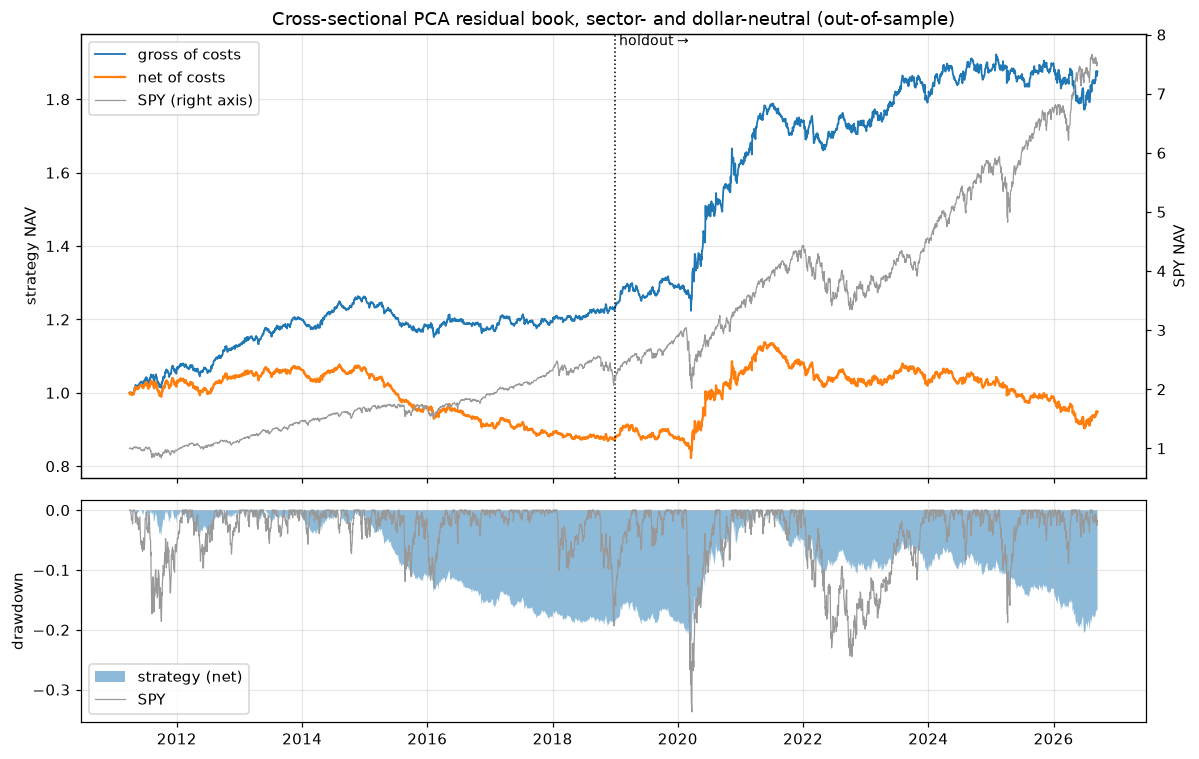

In [9]:
plot_equity(xs_bt, "Cross-sectional PCA residual book, sector- and dollar-neutral (out-of-sample)", spy_ret)

---
## Phase 8 — Comparison with the pairs book

Same period (from the first day both books trade), same engine, same costs. The pairs results are read from
`data/pairs_results.pkl`, written by Part 1. "Scaled to 10% vol" re-levers each book using its own full-period
volatility. That is a presentation device, not a tradable rule, and it puts the returns on the same scale. Sharpe
ratios are unaffected by leverage.

**Factor exposure check:** regress each book's daily net returns on SPY's. A properly neutral book should have a
beta close to zero; if not, the neutrality constraint has a bug.

In [10]:
def summary_row(gross, net, bt=None):
    X = np.column_stack([np.ones(len(net)), spy_ret.loc[net.index]])
    coef, *_ = np.linalg.lstsq(X, net.to_numpy(), rcond=None)
    resid_ = net.to_numpy() - X @ coef
    t_beta = coef[1] / np.sqrt(resid_.var(ddof=2) / ((X[:, 1] - X[:, 1].mean()) ** 2).sum())
    vol = net.std() * np.sqrt(TRADING_DAYS)
    return {"gross Sharpe": sharpe(gross), "net Sharpe": sharpe(net),
            "net Sharpe dev": sharpe(net.loc[:DEV_END]), "net Sharpe holdout": sharpe(net.loc[DEV_END:].iloc[1:]),
            "net ret/yr": ann_return(net), "net vol": vol, "net max DD": max_drawdown(net),
            "net ret @10% vol": ann_return(net * 0.10 / vol), "max DD @10% vol": max_drawdown(net * 0.10 / vol),
            "turnover x/yr": bt.turnover.mean() * TRADING_DAYS if bt is not None else np.nan,
            "beta to SPY": coef[1], "t(beta)": t_beta, "corr to SPY": net.corr(spy_ret.loc[net.index])}


books = {"Cross-sectional (this notebook)": xs_bt}
pairs_file = DATA_DIR / "pairs_results.pkl"
if pairs_file.exists():
    books = {"Pairs (Part 1)": pd.read_pickle(pairs_file)} | books
else:
    print("data/pairs_results.pkl not found: run 01_pairs_trading.ipynb first to include the pairs book.")
start = max(bt.index[0] for bt in books.values())
common = {name: bt.loc[start:] for name, bt in books.items()}
comparison = pd.DataFrame({name: summary_row(bt.gross_ret, bt.net_ret, bt) for name, bt in common.items()})
comparison["SPY buy & hold"] = summary_row(spy_ret.loc[start:], spy_ret.loc[start:])
comparison.loc["t(beta)", "SPY buy & hold"] = np.nan          # SPY on itself: beta is 1 by definition
print(f"Common period {start.date()} -> {prices.index[-1].date()}")
if len(common) == 2:
    print(f"correlation of the two books' daily net returns: "
          f"{common['Pairs (Part 1)'].net_ret.corr(common['Cross-sectional (this notebook)'].net_ret):+.2f}")
fmt = {r: "{:+.2f}" for r in ["gross Sharpe", "net Sharpe", "net Sharpe dev", "net Sharpe holdout", "beta to SPY", "t(beta)", "corr to SPY"]}
fmt |= {r: "{:+.1%}" for r in ["net ret/yr", "net vol", "net max DD", "net ret @10% vol", "max DD @10% vol"]}
fmt |= {"turnover x/yr": "{:.0f}"}
comparison.T.style.format(fmt, na_rep="-")

Common period 2011-03-31 -> 2026-09-14
correlation of the two books' daily net returns: +0.24


,gross Sharpe,net Sharpe,net Sharpe dev,net Sharpe holdout,net ret/yr,net vol,net max DD,net ret @10% vol,max DD @10% vol,turnover x/yr,beta to SPY,t(beta),corr to SPY
Pairs (Part 1),+1.11,+0.48,+0.38,+0.56,+1.5%,+3.3%,-6.3%,+4.4%,-18.4%,39,+0.04,+12.49,+0.20
Cross-sectional (this notebook),+0.79,-0.04,-0.44,+0.20,-0.3%,+5.4%,-23.7%,-0.9%,-40.0%,79,+0.04,+7.76,+0.12
SPY buy & hold,+0.85,+0.85,+0.77,+0.93,+14.0%,+17.1%,-33.7%,+8.4%,-20.8%,-,+1.00,-,+1.00


---
## Phase 9 — Robustness

Three questions:

1. **Is the result a knife-edge?** Vary the rebalance band and the cost.
2. **Is there leakage?** Replace the signal with a random one of the same frequency; the result should be ≈ 0
   gross and negative net.
3. **Does anything survive post-2015, and with slower execution?**

### 9.1 Sensitivity: rebalance band × cost (net Sharpe)

In [11]:
xs_sens = {}
for band in (0.5, 1.0, 2.0, 3.0):
    w = sector_neutral_decile_book(xs_z, xs_hl, SECTOR, band=band).loc[xs_w.index[0]:]
    for cost in (0, 2, 3, 5, 10):
        bt = run_backtest(w, prices.loc[w.index], cost_bps=cost)
        xs_sens[(band, cost)] = sharpe(bt.net_ret)
xs_sens = pd.Series(xs_sens).unstack().rename(index=lambda v: f"{v:g}")
xs_sens.index.name, xs_sens.columns.name = "rebalance band", "cost bps →"
xs_sens.style.format("{:+.2f}").background_gradient(cmap="RdYlGn", vmin=-1, vmax=1)

cost bps →,0,2,3,5,10
rebalance band,,,,,
0.5,+0.87,+0.25,-0.06,-0.68,-2.25
1,+0.82,+0.38,+0.16,-0.29,-1.41
2,+0.69,+0.40,+0.25,-0.04,-0.77
3,+0.60,+0.37,+0.26,+0.03,-0.53


**Break-even cost.** Net Sharpe as the all-in cost per dollar traded goes from 0 to 10 bps. Where the line crosses
zero is the most you could pay per trade and still make money.

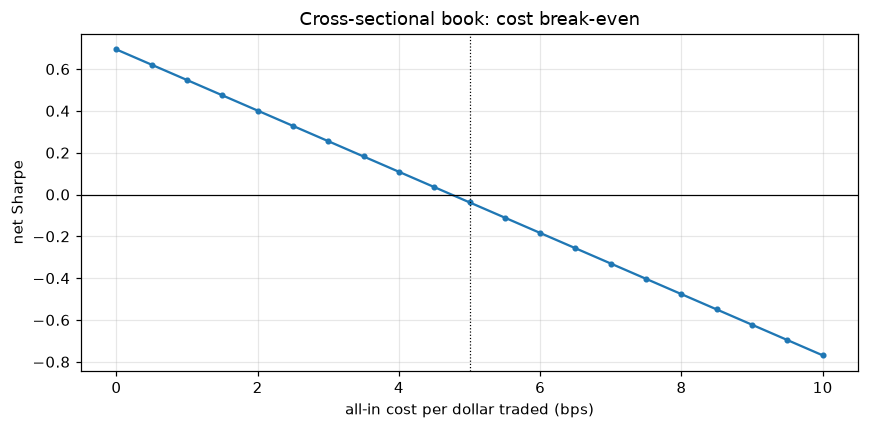

break-even cost: 4.7 bps per dollar traded (base case 5 bps)


In [12]:
cost_grid = np.arange(0, 10.5, 0.5)
breakeven_curve = pd.Series([sharpe(run_backtest(xs_w, prices.loc[xs_w.index], cost_bps=c).net_ret) for c in cost_grid],
                            index=cost_grid)
breakeven = float(np.interp(0, -breakeven_curve.to_numpy(), cost_grid))
ax = breakeven_curve.plot(figsize=(8, 4), marker=".")
ax.axhline(0, color="k", lw=0.8); ax.axvline(COST_BPS, color="k", ls=":", lw=0.8)
ax.set_xlabel("all-in cost per dollar traded (bps)"); ax.set_ylabel("net Sharpe"); ax.set_title("Cross-sectional book: cost break-even")
plt.tight_layout(); plt.show()
print(f"break-even cost: {breakeven:.1f} bps per dollar traded (base case {COST_BPS:.0f} bps)")

### 9.2 Leakage check: random signal with the same trading frequency

Keep the z-score time series exactly, but give each series to a randomly chosen *other* stock (a column
permutation). Same frequency, same turnover, no information. If this "random" book earned money gross, the engine
or the data would be leaking future information.

In [13]:
rand_rows = []
for seed in range(5):
    rng = np.random.default_rng(seed)
    perm = rng.permutation(xs_z.columns)
    z_rand = xs_z[perm].set_axis(xs_z.columns, axis=1)
    hl_rand = xs_hl[perm].set_axis(xs_hl.columns, axis=1)
    w_x = sector_neutral_decile_book(z_rand, hl_rand, SECTOR).loc[xs_w.index[0]:]
    bt_x = run_backtest(w_x, prices.loc[w_x.index])
    rand_rows.append({"gross Sharpe": sharpe(bt_x.gross_ret), "net Sharpe": sharpe(bt_x.net_ret)})
rand = pd.DataFrame(rand_rows, index=[f"random seed {s}" for s in range(5)])
rand.loc["mean of random"] = rand.mean()
rand.loc["real signal"] = [sharpe(xs_bt.gross_ret), sharpe(xs_bt.net_ret)]
rand.style.format("{:+.2f}")

,gross Sharpe,net Sharpe
random seed 0,-0.03,-1.22
random seed 1,-0.07,-1.26
random seed 2,+0.26,-0.94
random seed 3,+0.00,-1.20
random seed 4,-0.10,-1.30
mean of random,+0.01,-1.19
real signal,+0.79,-0.04


### 9.3 Post-2015, and execution one step later

The market-on-close assumption (signal computed with the close, traded at the close) is standard in the
literature, but in practice you'd compute the signal a few minutes before the close. The harshest alternative is
to trade at the **next day's open**: we feed the engine opening prices and lag the weights one day.

In [14]:
def ex_row(w, px_, lag=0):
    w = w.shift(lag).fillna(0) if lag else w
    bt = run_backtest(w, px_.loc[w.index])
    return {"net Sharpe": sharpe(bt.net_ret), "net Sharpe 2016+": sharpe(bt.net_ret.loc["2016":]),
            "net holdout": sharpe(bt.net_ret.loc[DEV_END:].iloc[1:]), "gross Sharpe": sharpe(bt.gross_ret)}


timing = pd.DataFrame({"trade at close t (base)": ex_row(xs_w, prices),
                       "trade at open t+1": ex_row(xs_w, opens, lag=1)}).T
timing.style.format("{:+.2f}")

,net Sharpe,net Sharpe 2016+,net holdout,gross Sharpe
trade at close t (base),-0.04,+0.01,+0.20,+0.79
trade at open t+1,-0.18,-0.11,+0.09,+0.63


---
## Phase 10 — Conclusions

The summary below is printed from the numbers computed above, so it always matches the notebook.

In [15]:
x = comparison["Cross-sectional (this notebook)"]
print(f"""CROSS-SECTIONAL BOOK  {start.date()} -> {prices.index[-1].date()}, {COST_BPS:.0f} bps per dollar traded + {BORROW_BPS_ANNUAL:.0f} bps/yr borrow

  net Sharpe {x['net Sharpe']:+.2f}  (development {x['net Sharpe dev']:+.2f}, holdout {x['net Sharpe holdout']:+.2f});  gross {x['gross Sharpe']:+.2f}
  turnover {x['turnover x/yr']:.0f}x/yr;  beta to SPY {x['beta to SPY']:+.3f};  exactly dollar- and sector-neutral at every trade
  break-even cost {breakeven:.1f} bps;  post-2015 net Sharpe {timing.loc['trade at close t (base)', 'net Sharpe 2016+']:+.2f};  random-signal gross Sharpe {rand.loc['mean of random', 'gross Sharpe']:+.2f} (should be ~0)""")

CROSS-SECTIONAL BOOK  2011-03-31 -> 2026-09-14, 5 bps per dollar traded + 50 bps/yr borrow

  net Sharpe -0.04  (development -0.44, holdout +0.20);  gross +0.79
  turnover 79x/yr;  beta to SPY +0.039;  exactly dollar- and sector-neutral at every trade
  break-even cost 4.7 bps;  post-2015 net Sharpe +0.01;  random-signal gross Sharpe +0.01 (should be ~0)


### What the results say

The PCA residual z-score clearly predicts returns: gross Sharpe ~0.7–0.9 in both periods, while a random signal
with the same turnover earns nothing. But the edge per trade is small (each name is held about two weeks). The
book is around break-even at 5 bps and positive at 2–3 bps, which is where a small book trading in the closing
auction actually sits. This is the well-documented economics of short-term reversal in mega-caps: it pays you for
providing liquidity, and it is only worth collecting with cheap execution.

Its value in the project is twofold. It is a second, low-correlation return stream (correlation ~0.2 with the pairs
book). It is also a demonstration of a fully neutral book: dollar- and sector-neutral at every trade, 2% name cap,
market beta ~0.04. The profitable strategy of the project is the pairs book in Part 1.

**Data-mining disclosure.** About 30 cross-sectional variants were tried while developing this notebook. Choices
were made on the 2011–2018 numbers, but the holdout numbers were printed alongside them, so the holdout is not
perfectly untouched. Treat the holdout Sharpe as optimistic. Survivorship bias in the universe works in the same
direction.

### What this backtest doesn't capture

Intraday price impact and adverse selection (a resting order gets filled precisely when the price is moving against
it), borrow availability and recalls on specific names (the 50 bps fee assumes everything is easy to borrow),
slippage beyond the flat 2 bps on less liquid names, and survivorship bias in the universe (current constituents
only). Results also assume market-on-close execution at the closing price used to compute the signal.

### What would change with real execution data

The fixed half-spread and slippage would be replaced by measured trade-by-trade fill quality (implementation
shortfall), costs would scale with order size relative to average daily volume, position limits would be set as a
fraction of ADV rather than a flat 2% cap, and the signal would be computed from prices a few minutes before the
close so that market-on-close orders are actually feasible.